In [2]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from pathlib import Path
import pandas as pd
import seaborn as sns
%load_ext autoreload
%autoreload 2

from fwh_analysis import FWHDataset, FWHPlotter

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


/home/abi/Documents/FWH/postprocess/aeroacoustics_postprocess/fwh_analysis.py:362: SyntaxWarning: invalid escape sequence '\l'
  ax.set_xlabel(f"Spatial Resolution ($\lambda% / d)")
/home/abi/Documents/FWH/postprocess/aeroacoustics_postprocess/fwh_analysis.py:365: SyntaxWarning: invalid escape sequence '\l'
  ax.set_xlabel(f"Normalised Radius (R / $\lambda$)")


In [ ]:
def p_element_plot(dataframe, title=None):
    """ Returns P vs Element Matrix as an alternative to P vs X Matrix """
    norm = mcolors.LogNorm(vmin = 1e-3, vmax=1e-1)
    cmap = cm.coolwarm

    fig, ax = plt.subplots(figsize=[8,6])
    color_val = cmap(norm(dataframe['error']))
    ax.scatter(dataframe['elements'] / 1000, dataframe['P'], color=color_val)

    sm = plt.cm.ScalarMappable(cmap = cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax)
    cbar.set_label("Log Error (%)")

    ax.set_xlabel(f"Element Count $(10^3)$")
    # ax.set_xscale('log')
    ax.set_ylabel("Temporal Resolution, P (Points Per Period)")
    ax.set_title(title)

    plt.show()

def line_plot(df, p_val=80, x_val=100, mach_number=0.0, radius=20.0):
    p = df[df['P'] == p_val].sort_values(by='X')
    x = df[df['X'] == x_val].sort_values(by='P')

    fig, (ax1, ax2) = plt.subplots(1,2, sharey=True, figsize=(12,4))
    ax1.scatter(p['X'], p['error'])
    ax1.plot(p['X'], p['error'])
    ax1.set_yscale('log')
    ax1.set_ylim(1e-3, 5e-1)
    ax1.set_xlabel(f"Spatial Resolution, X ($\lambda$/d)")
    ax1.set_ylabel("Log Error (%)")
    ax1.grid(True, which='both')
    ax1.set_title(f'Constant P at {p_val}')

    ax2.scatter(x['P'], x['error'])
    ax2.plot(x['P'], x['error'])
    ax2.set_xlabel(f"Temporal Resolution, P ($f_{{sample}} / f_{{s}}$)")
    ax2.grid(True, which='both')
    ax2.set_title(f'Constant X at {x_val}')

    fig.suptitle(f'Error vs Parameterised Time Step/Grid Size, M={mach_number}, R={radius}')
    plt.show()

<>:31: SyntaxWarning: invalid escape sequence '\l'
<>:31: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_136853/13125497.py:31: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_xlabel(f"Spatial Resolution $\lambda$/d")


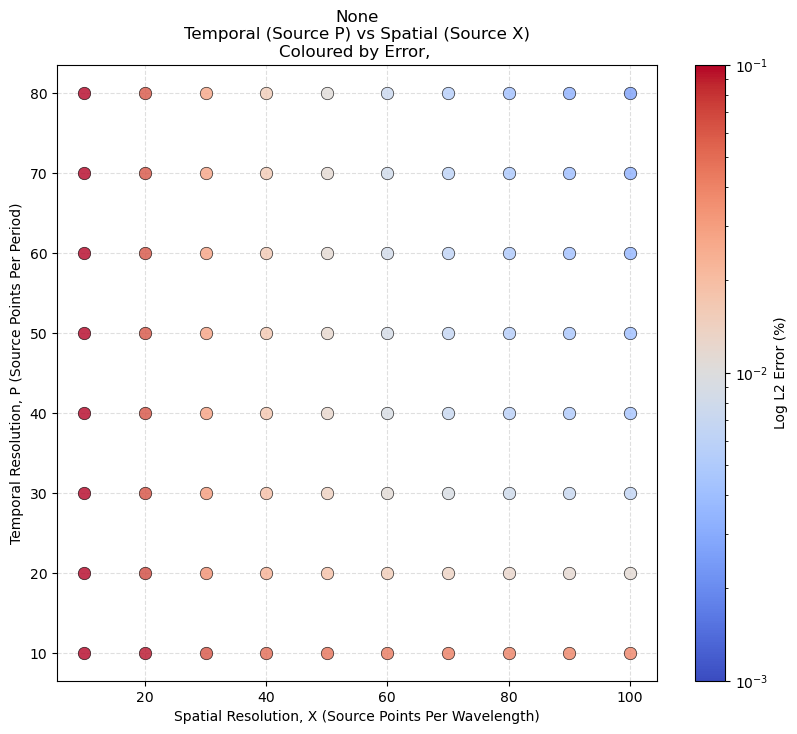

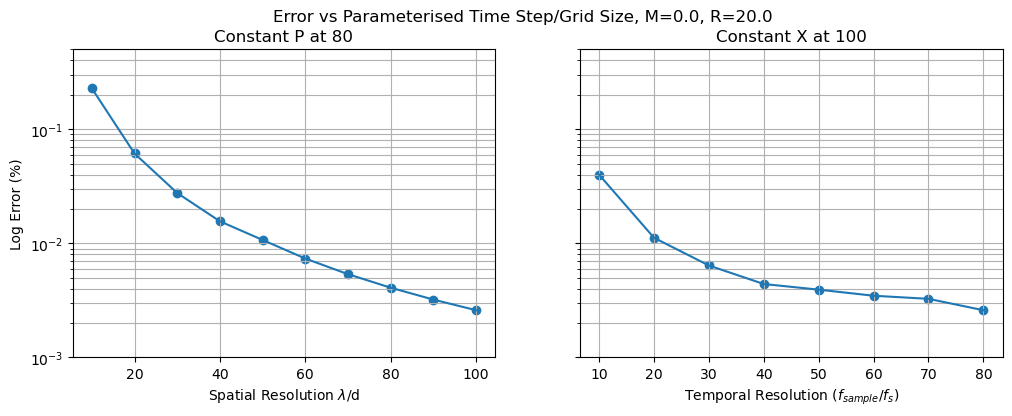

In [96]:
#### Stationary Single Monopole ####
# Setup
filepath = Path('data_260610/single_mono/')
data_m00 = FWHDataset.compile_fwh_batch(filepath)
analytical = FWHDataset(filepath / 'ana_M00.dat')

df_00 = pd.DataFrame(data_m00)
df_00['X'] = df_00['X'].round()
df_00['P'] = df_00['P'].round()

# X vs P Matrix
FWHPlotter.plot_px_parameter_space(data_m00, use_doppler=False, legend=False)

# Line Plot P vs Error, X vs Error
line_plot(df_00, 80, 100)

In [67]:
df_00[df_00['X'] == df_00['X'].max()].sort_values(by='P')

,mach,cfl,dt,P,X,error,elements,batch_name
17,0.0,2.0,0.012566,50.001475,100.002949,0.003926,3481,single_mono


In [ ]:
dir_list = []
for file in filepath.glob("*X100"):
    dir_list.extend(file)
for i in dir_list:
    FWHPlotter.plot_cfl_convergence_by_mach(directory=(i for i in dir_list), analysis='dt',
                                        ref_val = (100,20), analytical_refs=analytical)

In [44]:
for file in filepath.glob('P80*_M00.dat'):
    print(file)

data_260610/single_mono/P80_X10_M00.dat
data_260610/single_mono/P80_X60_M00.dat
data_260610/single_mono/P80_X90_M00.dat
data_260610/single_mono/P80_X80_M00.dat
data_260610/single_mono/P80_X30_M00.dat
data_260610/single_mono/P80_X100_M00.dat
data_260610/single_mono/P80_X20_M00.dat
data_260610/single_mono/P80_X40_M00.dat
data_260610/single_mono/P80_X50_M00.dat
data_260610/single_mono/P80_X70_M00.dat


In [ ]:
for filename in glob2.glob()

In [39]:
FWHDataset.compile_fwh_batch(x100)

[]

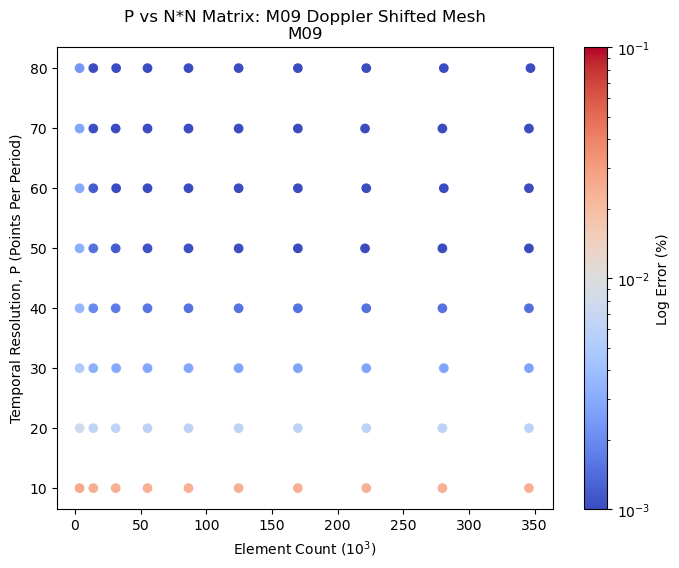

In [35]:
df_M09 = pd.DataFrame(FWHDataset.compile_fwh_batch('data_260603/test_M09', use_doppler=True))
p_element_plot(df_M09,
               title='P vs N*N Matrix: M09 Doppler Shifted Mesh\nM09')

In [ ]:
df_M00 = pd.DataFrame(FWHDataset.compile_fwh_batch(Path("data_260610/single_mono")))

df_M00.sort_values(by=['error'], ascending=False)


In [ ]:
FWHPlotter.plot_px_contour_space(df_M00, use_doppler=False)

In [ ]:
df_M0905 = pd.DataFrame(FWHDataset.compile_fwh_batch("data_260609/test_M09_M05_mesh", use_doppler=True))
p_element_plot(df_M0905,
               title='P vs N*N Matrix: M05 Doppler Shifted Mesh\n M09')

In [ ]:
df_M09nd = pd.DataFrame(FWHDataset.compile_fwh_batch('data_260609/test_M09_non_doppler_mesh', use_doppler=False))
p_element_plot(df_M09nd, 
               title='P vs N*N Matrix: Freestream Wavelength Mesh\n M09')

In [ ]:
filepath = Path('data_260609/test_M09_non_doppler_mesh/')
ana = FWHDataset(filepath / 'ana_M90.dat')
p80_x100 = FWHDataset(filepath / 'P80_X100_M90.dat')
p40_x100 = FWHDataset(filepath / 'P40_X100_M90.dat')
p10_x100 = FWHDataset(filepath / 'P10_X100_M90.dat')

FWHPlotter.plot_pressure(ana, p80_x100, p40_x100, p10_x100, ref_col='P_obs', labels=[
    'P80, X100, f_sample = 1273 Hz, grid_count = 3481',
    'P40, X100, f_sample = 63.7 Hz, grid_count = 3481',
    'P10, X100, f_sample = 15.9 Hz, grid_count = 3481'
],
title="Non-Doppler Shifted Spatial and Temporal Resolutions\nM=0.9, fsource=1.6 Hz, Doppler f=16 Hz")

In [ ]:
p80_x50 = FWHDataset(filepath / 'P80_X50_M90.dat')
p80_x10 = FWHDataset(filepath / 'P80_X10_M90.dat')

FWHPlotter.plot_pressure(ana, p80_x100, p80_x50, p80_x10, ref_col='P_obs', labels=[
    'P80, X100, f_sample = 1273 Hz, grid_count = 3481',
    'P80, X50, f_sample = 1273 Hz, grid_count = 841',
    'P80, X10, f_sample = 1273 Hz, grid_count = 36'
], title="Non-Doppler Shifted Spatial and Temporal Resolutions\n" \
"M=0.9, lambda_source=213 m, Doppler Lambda=21.3 m"
)

In [ ]:
folders = [
    'data_260609/multi_obs/obs_01',
    'data_260609/multi_obs/obs_02',
    'data_260609/multi_obs/obs_03',
    'data_260609/multi_obs/obs_04',
    'data_260609/multi_obs/obs_05',
]

master = []
for folder in folders:
    master.extend(FWHDataset.compile_fwh_batch(folder, use_doppler=True))

df = pd.DataFrame(master)
obs_01 = df[df['batch_name']=='obs_01']
obs_02 = df[df['batch_name']=='obs_02']
obs_03 = df[df['batch_name']=='obs_03']
obs_04 = df[df['batch_name']=='obs_04']
obs_05 = df[df['batch_name']=='obs_05']

In [ ]:
print("All mean:", df['error'].mean(), "All median:", df['error'].median())

In [ ]:
medians = [
    obs_01['error'].median(),
    obs_02['error'].median(),
    obs_03['error'].median(),
    obs_04['error'].median(),
    obs_05['error'].median(),
]
std_dev = [
    obs_01['error'].std(),
    obs_02['error'].std(),
    obs_03['error'].std(),
    obs_04['error'].std(),
    obs_05['error'].std(),
]
maxs = [
    obs_01['error'].max(),
    obs_02['error'].max(),
    obs_03['error'].max(),
    obs_04['error'].max(),
    obs_05['error'].max(),
]

mins = [
    obs_01['error'].min(),
    obs_02['error'].min(),
    obs_03['error'].min(),
    obs_04['error'].min(),
    obs_05['error'].min(),
]

means = [
    obs_01['error'].mean(),
    obs_02['error'].mean(),
    obs_03['error'].mean(),
    obs_04['error'].mean(),
    obs_05['error'].mean(),
]

labels = ['obs_01', 'obs_02', 'obs_03', 'obs_04', 'obs_05']

fig, ax = plt.subplots()
ax.bar(labels, medians, edgecolor='black', color='steelblue')
ax.errorbar(labels, medians, yerr=means, c='r')
ax.set_yscale('log')
ax.set_ylim(1e-3, 1e-1)
ax.set_ylabel('Median L2 Error (%)')
ax.grid(True, axis='y', ls='--', alpha=0.5)
ax.set_title("Multiple Observer Test - Median Error of Each Observer\n Errorbar: Std Dev")

plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))

# 1. Create the Box Plot
# showfliers=True #keeps the outlier dots visible (your coarse grid runs)
sns.boxplot(data=df, x='batch_name', y='error', palette='coolwarm', 
            boxprops=dict(edgecolor='black'), medianprops=dict(color='red', linewidth=2),
            showfliers=False, ax=ax)

medians = df.groupby('batch_name')['error'].median()
obs_names = ['obs_01', 'obs_02', 'obs_03', 'obs_04', 'obs_05']

for i, obs in enumerate(obs_names):
    median_val = medians[obs]
    text_label = f"{median_val:.2e}" 
    ax.text(i, median_val * 1.05, text_label, 
            horizontalalignment='center', size='small', color='black', weight='bold')

ax.set_yscale('log')
ax.set_ylabel('L2 Error (%)')
ax.set_ylim(5e-4, 5e-2)
ax.set_xlabel('Observer ID (Front to Rear)')
ax.set_title('Multiple Observer Error Variance - Interquartile Range')
ax.grid(True, axis='y', linestyle='--', alpha=0.6)

plt.show()

In [ ]:
df.sort_values(by=['error','batch_name'], ascending=False).head(10)

In [ ]:
# import seaborn as sns
# import matplotlib.pyplot as plt
# import numpy as np

# fig, ax = plt.subplots(figsize=(8, 6))

# # estimator=np.median calculates the central tendency
# # errorbar='sd' draws the standard deviation lines to show variance across X and P
# sns.barplot(data=df, x='batch_name', y='error', estimator=np.median, 
#             errorbar='sd', palette='coolwarm', edgecolor='black', ax=ax)

# ax.set_yscale('log')
# ax.set_ylabel('Median L2 Error (%)')
# ax.set_xlabel('Observer')
# ax.set_title('Error Distribution Across Observer Arc')
# ax.grid(True, axis='y', linestyle='--', alpha=0.6)

# plt.show()

In [ ]:
# filepath = Path(f"{folders[0]}/")
# ana = FWHDataset(filepath / "ana_M50.dat")
# p10_x10 = FWHDataset(filepath / "P10_X10_M50.dat")
# p80_x100 = FWHDataset(filepath / "P80_X100_M50.dat")
# FWHPlotter.plot_pressure(ana, p10_x10, p80_x100, ref_col='P_obs')

In [ ]:
title = ['Observer 1 (100, 0, 0)', 
         'Observer 2 (70.7, 70.7, 0)', 
         'Observer 3 (0, 100, 0)', 
         'Observer 4 (-70.7, 70.7, 0)', 
         'Observer 5 (-100, 0, 0)']

for i,j in zip(folders, title):
    data = FWHDataset.compile_fwh_batch(Path(i), use_doppler=True)
    FWHPlotter.plot_px_parameter_space(data, legend=False, add_title=j)

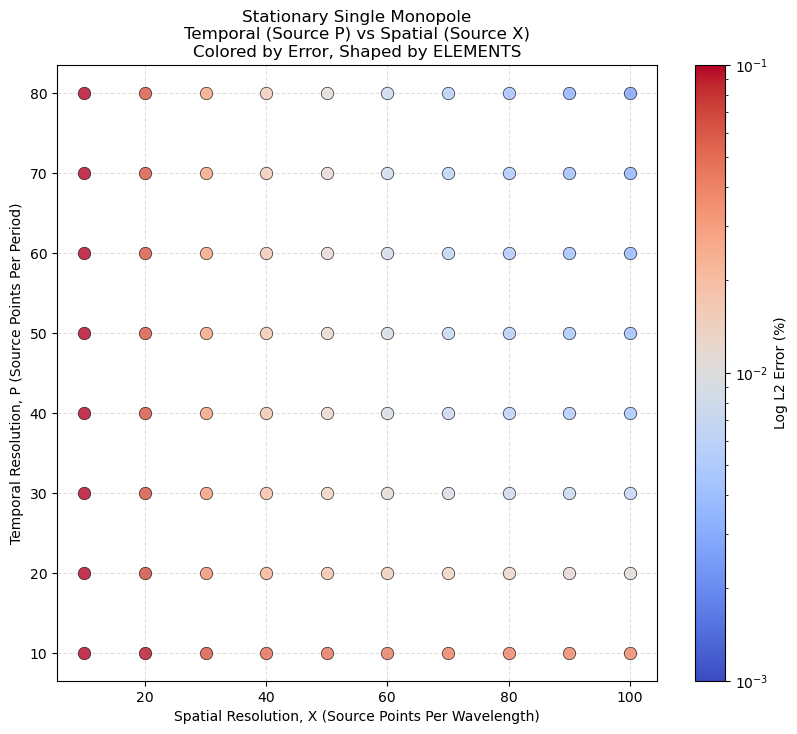

In [14]:
data_single_mono = 'data_260610/single_mono/'
single_mono = FWHDataset.compile_fwh_batch(Path(data_single_mono))
FWHPlotter.plot_px_parameter_space(single_mono, use_doppler=False,
                                   legend=False, add_title="Stationary Single Monopole")

In [ ]:
np.log(2) - np.log(0)

In [ ]:
folders = [
    'data_260610/dual_mono/obs_01',
    'data_260610/dual_mono/obs_02',
    'data_260610/dual_mono/obs_03',
    'data_260610/dual_mono/obs_04',
    'data_260610/dual_mono/obs_05',
]

master = []
for folder in folders:
    master.extend(FWHDataset.compile_fwh_batch(folder, use_doppler=False, error_method='rmse'))

df = pd.DataFrame(master)
obs_01 = df[df['batch_name']=='obs_01']
obs_02 = df[df['batch_name']=='obs_02']
obs_03 = df[df['batch_name']=='obs_03']
obs_04 = df[df['batch_name']=='obs_04']
obs_05 = df[df['batch_name']=='obs_05']
obs_06 = df[df['batch_name']=='obs_06']
obs_07 = df[df['batch_name']=='obs_07']
obs_08 = df[df['batch_name']=='obs_08']

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=df, x='batch_name', y='error', palette='coolwarm', 
            boxprops=dict(edgecolor='black'), medianprops=dict(color='red', linewidth=2),
            showfliers=False, ax=ax)

medians = df.groupby('batch_name')['error'].median()
obs_names = ['obs_01', 'obs_02', 'obs_03', 'obs_04', 'obs_05', 'obs_06', 'obs_07', 'obs_08']

for i, obs in enumerate(obs_names):
    median_val = medians[obs]
    text_label = f"{median_val:.2e}" 
    ax.text(i, median_val * 1.05, text_label, 
            horizontalalignment='center', size='small', color='black', weight='bold')

# ax.set_yscale('log')
ax.set_ylabel('RMSE Error')
ax.set_xlabel('Observer ID (Front to Rear)')
ax.set_title('Error Variance (Interquartile Range & Outliers)')
ax.grid(True, axis='y', linestyle='--', alpha=0.6)

plt.show()

In [ ]:
folders = [
    # 'data_260610/dual_mono/obs_01',
    'data_260610/dual_mono/obs_02',
    'data_260610/dual_mono/obs_03',
    'data_260610/dual_mono/obs_04',
    # 'data_260610/dual_mono/obs_05',
    'data_260610/dual_mono/obs_06',
    'data_260610/dual_mono/obs_07',
    'data_260610/dual_mono/obs_08',
]

master = []
for folder in folders:
    master.extend(FWHDataset.compile_fwh_batch(folder, use_doppler=False, error_method='l2'))

df = pd.DataFrame(master)
# obs_01 = df[df['batch_name']=='obs_01']
obs_02 = df[df['batch_name']=='obs_02']
obs_03 = df[df['batch_name']=='obs_03']
obs_04 = df[df['batch_name']=='obs_04']
# obs_05 = df[df['batch_name']=='obs_05']
obs_06 = df[df['batch_name']=='obs_06']
obs_07 = df[df['batch_name']=='obs_07']
obs_08 = df[df['batch_name']=='obs_08']

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=df, x='batch_name', y='error', palette='coolwarm', 
            boxprops=dict(edgecolor='black'), medianprops=dict(color='red', linewidth=2),
            showfliers=False, ax=ax)

medians = df.groupby('batch_name')['error'].median()
obs_names = ['obs_02', 'obs_03', 'obs_04','obs_06', 'obs_07', 'obs_08']

for i, obs in enumerate(obs_names):
    median_val = medians[obs]
    text_label = f"{median_val:.2e}" 
    ax.text(i, median_val * 1.05, text_label, 
            horizontalalignment='center', size='small', color='black', weight='bold')

ax.set_yscale('log')
ax.set_ylabel('RMSE Error')
ax.set_xlabel('Observer ID (Front to Rear)')
ax.set_title('Error Variance (Interquartile Range & Outliers)')
ax.grid(True, axis='y', linestyle='--', alpha=0.6)

plt.show()

In [ ]:
FWHPlotter.plot_pressure(
    FWHDataset(Path('data_260610/dual_mono/obs_01/ana_M00.dat')),
    FWHDataset(Path('data_260610/dual_mono/obs_01/P80_X100_M00.dat')),
    ref_col='P_obs',
    title="Dual Monopole: Observer 01, P80 X100",
    labels=['Numerical']
)

In [ ]:
FWHPlotter.plot_pressure(
    FWHDataset(Path('data_260610/dual_mono/obs_03/ana_M00.dat')),
    FWHDataset(Path('data_260610/dual_mono/obs_03/P80_X100_M00.dat')),
    ref_col='P_obs',
    title='Dual Monopole: Observer 03, P80 X100',
    labels=['Numerical']
)

In [ ]:
FWHPlotter.plot_pressure(
    FWHDataset(Path('data_260610/dual_mono/obs_02/ana_M00.dat')),
    FWHDataset(Path('data_260610/dual_mono/obs_02/P80_X100_M00.dat')),
    ref_col='P_obs',
    title='Dual Monopole: Observer 02, P80, X100',
    labels=['Numerical']
)